# 🚀 Модуль 1. Урок 5. AI Copilot в Excel: генерация сложных формул и автоматизация отчетов

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_01_excel/lesson_05_ai_copilot_excel_formulas.ipynb)

## 📌 Бизнес-контекст и методология
Microsoft 365 Copilot и Google Duet AI кардинально изменили работу с таблицами.
Больше не нужно мучительно конструировать вложенные формулы из 5 уровней скобок (`INDEX(MATCH(IF(...)))`).
Аналитик описывает задачу на естественном языке, а AI формирует формулу, валидирует граничные условия и объясняет механику расчета.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: AI Промпты для генерации формул Excel
Сравним скорость и качество генерации сложных расчетов.

In [2]:
# Демонстрация: Автоматическая генерация аналитических признаков
# Задача промпта: "Пометить клиентов с покупками >$500 и датой заказа в текущем квартале как 'Priority VIP'"
df_customers_sample = pd.DataFrame({
    'client_id': [1, 2, 3, 4],
    'spent': [650, 320, 890, 150],
    'days_ago': [12, 45, 80, 5]
})

df_customers_sample['status'] = np.where(
    (df_customers_sample['spent'] > 500) & (df_customers_sample['days_ago'] <= 30),
    'Priority VIP', 'Standard'
)
display(df_customers_sample)

,client_id,spent,days_ago,status
0,1,650,12,Priority VIP
1,2,320,45,Standard
2,3,890,80,Standard
3,4,150,5,Standard


## 📊 Визуализация бизнес-кейса: Скорость разработки формул с Copilot
Сравним затраты времени аналитика на написание формул разной степени сложности.

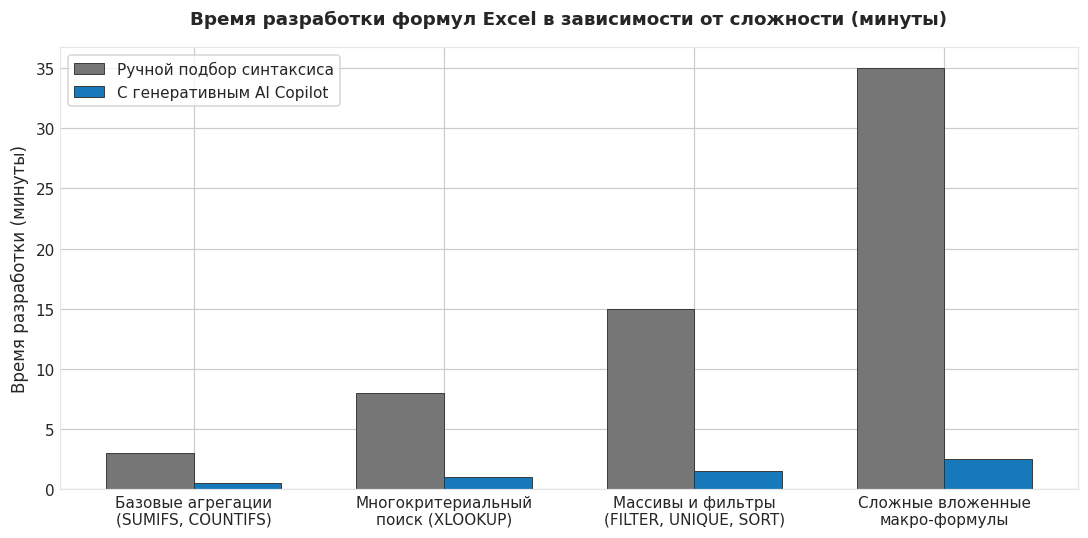

In [3]:
# Построение графика бенчмарка продуктивности
complexity = ['Базовые агрегации\n(SUMIFS, COUNTIFS)', 'Многокритериальный\nпоиск (XLOOKUP)', 'Массивы и фильтры\n(FILTER, UNIQUE, SORT)', 'Сложные вложенные\nмакро-формулы']
manual_min = [3, 8, 15, 35]
copilot_min = [0.5, 1.0, 1.5, 2.5]

fig, ax = plt.subplots(figsize=(10, 5), dpi=110)
x = np.arange(len(complexity))
width = 0.35

ax.bar(x - width/2, manual_min, width, label='Ручной подбор синтаксиса', color=SECONDARY, edgecolor='#333333', linewidth=0.6)
ax.bar(x + width/2, copilot_min, width, label='С генеративным AI Copilot', color=PRIMARY, edgecolor='#333333', linewidth=0.6)

ax.set_title("Время разработки формул Excel в зависимости от сложности (минуты)", fontsize=12, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(complexity, fontsize=10)
ax.set_ylabel("Время разработки (минуты)", fontsize=11)
ax.legend(frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Проверка количества Priority VIP
Посчитайте количество клиентов со статусом `Priority VIP` в `df_customers_sample`.

In [4]:
### ВАШ КОД ЗДЕСЬ
vip_count = (df_customers_sample['status'] == 'Priority VIP').sum()
print(f"Количество Priority VIP: {vip_count}")

assert vip_count == 1, "Должен быть ровно 1 Priority VIP клиент"
print("✅ Тест успешно пройден: логика формулы подтверждена!")

Количество Priority VIP: 1
✅ Тест успешно пройден: логика формулы подтверждена!


### 💡 Формула идеального промпта для Excel Copilot
Указывайте в промпте: 1) Целевую колонку, 2) Формат исходных данных, 3) Условия фильтрации, 4) Желаемое поведение при ошибке (например, `ЕСЛИОШИБКА`).